# 05 — V-Final: Whisper-large-v3 + LoRA + SpecAugment + oversampling thuật ngữ hiếm, beam 5

> Notebook trình bày, **không huấn luyện lại**. Mọi bảng và hình được tính từ file kết quả đã lưu trong `saved/`, chạy lại an toàn trên CPU. Log huấn luyện đã được rút gọn (bỏ thanh tiến độ, giữ mọi kết quả eval); bản đầy đủ nằm trong `ASR/notebooks/local` và `ASR/local/logs`.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
S = next(p / 'saved' for p in [Path.cwd(), *Path.cwd().parents] if (p / 'saved/tables').is_dir())
T = S / 'tables'
def js(rel): return json.loads((S / rel).read_text(encoding='utf-8'))
def show_log(name): print((S / 'logs' / name).read_text(encoding='utf-8'))
def history(name): return js(f'runs/{name}_trainer_state.json')['log_history']
pd.set_option('display.precision', 2)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
C = {'Baseline 1': '#7E9C9B', 'Baseline 2': '#A9C2C0', 'V1': '#0F4E57', 'V2': '#1A6771', 'V-Final': '#FFB21A'}

| Lỗi thấy được ở V1, V2 | Thay đổi ở V-Final |
|---|---|
| lr 1e-3 phân kỳ; train tiếp (V2) không sửa được | huấn luyện lại từ đầu, lr 1e-4 |
| quá khớp về cuối huấn luyện | SpecAugment: che 5% thời gian + 5% tần số |
| thuật ngữ hiếm, chưa gặp bị sai nhiều | oversampling clip chứa thuật ngữ xuất hiện ≤ 5 lần, lặp × 3 |
| backbone nhỏ | Whisper-large-v3, 1,55 tỉ tham số, đóng băng |
| lỗi giải mã | beam 5, chọn trên DEV trước khi xem TEST |

Huấn luyện trên Train chính thức của 4 nguồn để chấm được trên đúng TEST/HARD của paper. Colab A100 80 GB, bf16.

In [2]:
print((S / 'configs/VFinal.yaml').read_text(encoding='utf-8'))

# O3W — O2 + resampling against the long tail of medical terms: ViMedCSS TRAIN clips holding a term seen <= 5 times
# are repeated 3x in total (asr/data.py::_oversample_rare_terms). One variable vs O2.
model:
  name: openai/whisper-large-v3
  lora:
    r: 32
    alpha: 64
    dropout: 0.05
    target_modules: [q_proj, k_proj, v_proj, out_proj, fc1, fc2]
  spec_augment:
    mask_time_prob: 0.05
    mask_time_length: 10
    mask_feature_prob: 0.05
    mask_feature_length: 10

data:
  train_exclude: v3_train_exclude.json   # silent clips and labels denser than 16 tokens/s (ids are split-independent)
  term_oversample:
    source: ViMedCSS
    max_count: 5
    repeat: 3

train:
  epochs: 2
  batch_size: 32
  grad_accum: 1              # effective batch 32, as V1-V5
  lr: 1.0e-4                 # large model: half of V5's 2e-4 (V1 at 1e-3 diverged)
  warmup_ratio: 0.05
  fp16: false
  bf16: true                 # A100
  gradient_checkpointing: true
  eval_strategy: epoch       # evaluates a

**Lệnh đã chạy — huấn luyện trên Colab** (chép từ `ASR/colab_budget.ipynb`, ô 4; chỉ để xem)

```python
EXP = 'O3W_whisper_large_v3_lora_official_termos'
run('scripts/train.py', EXP)
```

**Lệnh đã chạy — DEV greedy và beam 5** (chép từ `ASR/colab_budget.ipynb`, ô 6; chỉ để xem)

```python
evaluate_once(EXP)
evaluate_once(EXP, beams=5)
import pandas as pd
rows = []
for name in ['dev', 'dev_beam5']:
    m = dev_metrics(EXP, name)
    rows.append(dict(exp=EXP, decode=name, wer=100*m['overall']['wer'], vimedcss=100*m['by_source']['ViMedCSS']['wer'],
                     term_recall=100*m['overall']['cs_term_recall'], truncated=m['overall']['n_truncated']))
table = pd.DataFrame(rows).sort_values('wer')
display(table.round(2))
FINAL = table.iloc[0].to_dict()
print('Hệ cuối:', FINAL)
```

**Lệnh đã chạy — chốt mô hình trước khi giải mã TEST** (chép từ `ASR/colab_budget.ipynb`, ô 7; chỉ để xem)

```python
# Freeze: ghi lại hệ cuối (config, sha256 adapter, cách giải mã, DEV) TRƯỚC khi giải mã TEST. Không ghi đè.
import hashlib, datetime, yaml
exp = FINAL['exp']
out = f'{PROJECT}/reports/final_freeze_official'
assert not os.path.exists(f'{out}/freeze.json'), 'đã chốt rồi, không chốt lại'
assert not any(os.path.exists(f'{PROJECT}/experiments/{exp}/eval/{s}') for s in ('test', 'test_beam5', 'hard', 'hard_beam5')), 'đã có TEST'
sha = lambda p: hashlib.sha256(open(p, 'rb').read()).hexdigest()
record = dict(frozen_at=datetime.datetime.now().isoformat(timespec='seconds'), final_system=exp,
              num_beams=5 if FINAL['decode'] == 'dev_beam5' else 1,
              config=yaml.safe_load(open(f'{PROJECT}/experiments/{exp}/config.yaml')),
              adapter_sha256=sha(f'{PROJECT}/experiments/{exp}/final/adapter_model.safetensors'),
              selection='lowest official-DEV WER of O3W greedy vs beam 5; TEST not decoded yet',
              dev_table=table.round(4).to_dict('records'))
os.makedirs(out, exist_ok=True)
json.dump(record, open(f'{out}/freeze.json', 'w'), ensure_ascii=False, indent=1)
print('Đã chốt:', exp, 'beam', record['num_beams'])
```

**Lệnh đã chạy — TEST và HARD, mỗi tập một lần** (chép từ `ASR/colab_budget.ipynb`, ô 9; chỉ để xem)

```python
freeze = json.load(open(f'{PROJECT}/reports/final_freeze_official/freeze.json'))
beams = 5 if freeze['num_beams'] == 5 else None
for split in ['hard', 'test']:
    evaluate_once(freeze['final_system'], split, beams)
for exp in ['B0_phowhisper_small_zeroshot', 'B2_phowhisper_large_zeroshot', 'B3_whisper_large_v3_zeroshot']:
    for split in ['hard', 'test']:
        evaluate_once(exp, split)
```

## Nhật ký lần chạy trên Colab

In [3]:
recs = [json.loads(l) for l in (S / 'runs/VFinal_runs.jsonl').read_text(encoding='utf-8').splitlines()]
pd.DataFrame([{'thời điểm': r['time'], 'việc': r['kind'], 'thiết bị': r['device'], 'số clip train': r.get('n_train', ''), 'torch': r['versions']['torch']} for r in recs])

,thời điểm,việc,thiết bị,số clip train,torch
0,2026-10-30T02:23:41,train,NVIDIA A100-SXM4-80GB,29864,2.11.0+cu130
1,2026-10-30T04:49:01,eval:dev,NVIDIA A100-SXM4-80GB,,2.11.0+cu130
2,2026-10-30T05:14:46,eval:dev_beam5,NVIDIA A100-SXM4-80GB,,2.11.0+cu130
3,2026-10-30T05:19:07,eval:hard_beam5,NVIDIA A100-SXM4-80GB,,2.11.0+cu130
4,2026-10-30T06:26:27,eval:test_beam5,NVIDIA A100-SXM4-80GB,,2.11.0+cu130


In [4]:
fz = js('runs/VFinal_freeze.json')
print(json.dumps(fz, ensure_ascii=False, indent=2)[:1500])

{
  "frozen_at": "2026-10-30T05:14:49",
  "final_system": "O3W_whisper_large_v3_lora_official_termos",
  "num_beams": 5,
  "config": {
    "model": {
      "name": "openai/whisper-large-v3",
      "lora": {
        "r": 32,
        "alpha": 64,
        "dropout": 0.05,
        "target_modules": [
          "q_proj",
          "k_proj",
          "v_proj",
          "out_proj",
          "fc1",
          "fc2"
        ]
      },
      "spec_augment": {
        "mask_time_prob": 0.05,
        "mask_time_length": 10,
        "mask_feature_prob": 0.05,
        "mask_feature_length": 10
      }
    },
    "data": {
      "train_exclude": "v3_train_exclude.json",
      "term_oversample": {
        "source": "ViMedCSS",
        "max_count": 5,
        "repeat": 3
      }
    },
    "train": {
      "epochs": 2,
      "batch_size": 32,
      "grad_accum": 1,
      "lr": 0.0001,
      "warmup_ratio": 0.05,
      "fp16": false,
      "bf16": true,
      "gradient_checkpointing": true,
      "eva

Log loss từng bước của V-Final nằm trong checkpoint trên Google Drive, chưa tải về máy, nên chưa có đường cong huấn luyện ở đây.

## Chọn cách giải mã trên DEV, rồi TEST/HARD

In [5]:
rows = {}
for k, lab in [('dev', 'DEV greedy'), ('dev_beam5', 'DEV beam 5'), ('test_beam5', 'TEST cả 4 nguồn, beam 5'), ('hard_beam5', 'ViMedCSS HARD, beam 5')]:
    m = js(f'metrics/VFinal_{k}.json'); o = m['overall']
    rows[lab] = {'WER %': 100 * o['wer'], 'CER %': 100 * o['cer'], 'Recall thuật ngữ %': 100 * o.get('cs_term_recall', float('nan')), 'số clip': o['n_utts'], 'RTF (A100)': m.get('rtf_decode_only')}
t = pd.DataFrame(rows).T.astype({'số clip': int})
t['RTF (A100)'] = t['RTF (A100)'].map('{:.3f}'.format)
t

,WER %,CER %,Recall thuật ngữ %,số clip,RTF (A100)
DEV greedy,15.52,12.54,79.21,5168,0.019
DEV beam 5,15.07,12.35,81.30,5168,0.038
"TEST cả 4 nguồn, beam 5",14.94,11.85,79.87,6659,0.037
"ViMedCSS HARD, beam 5",16.42,11.80,50.26,658,0.047


## So với mô hình chưa huấn luyện và với paper (ViMedCSS TEST/HARD)

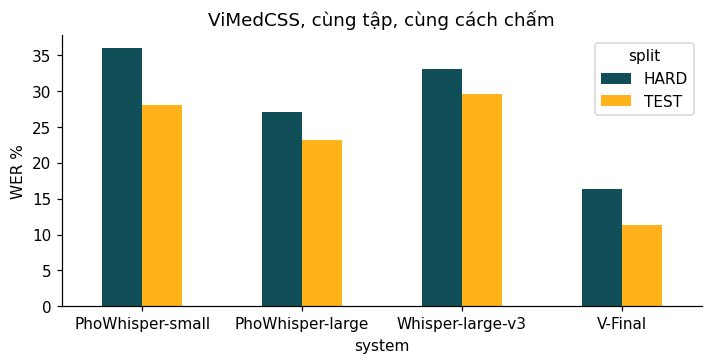

split,HARD,TEST
system,,
PhoWhisper-small,36.04,28.02
PhoWhisper-large,27.14,23.14
Whisper-large-v3,33.14,29.61
V-Final,16.42,11.40


In [6]:
s = pd.read_csv(T / 'same_metric_official.csv'); p = pd.read_csv(T / 'same_metric_paper.csv')
lab = {'B0': 'PhoWhisper-small', 'B2': 'PhoWhisper-large', 'B3': 'Whisper-large-v3', 'O3W': 'V-Final'}
w = s[s.system.isin(lab)].assign(system=lambda x: x.system.map(lab)).pivot_table(index='system', columns='split', values='wer').reindex(list(lab.values()))
ax = w.plot.bar(figsize=(7.5, 3.2), rot=0, color=['#0F4E57', '#FFB21A'])
ax.set_ylabel('WER %'); ax.set_title('ViMedCSS, cùng tập, cùng cách chấm'); plt.show()
w

In [7]:
pd.read_csv(T / 'official_test_by_source.csv').set_index('system').rename(index={'B0': 'PhoWhisper-small', 'B2': 'PhoWhisper-large', 'B3': 'Whisper-large-v3', 'O3W': 'V-Final'}).drop(columns='description')

,wer_FLEURS,wer_VIVOS,wer_ViMedCSS,wer_VietMed,wer_all
system,,,,,
PhoWhisper-small,12.19,6.28,28.02,25.19,22.87
PhoWhisper-large,8.36,4.61,23.14,24.04,20.18
Whisper-large-v3,8.36,12.28,29.61,73.94,47.27
V-Final,6.97,7.03,11.40,20.43,14.94


Số công bố trong paper ViMedCSS (WER %, CS-WER %). Hệ tốt nhất của paper là PhoWhisper-Small + AG: TEST 23,67, HARD 33,73. Chênh lệch cách chấm 5–10 điểm (notebook `02_Baseline`) nên đây chưa phải xếp hạng.

In [8]:
p.set_index(['split', 'system'])

,,wer,cer,cs_wer,n_wer
split,system,,,,
TEST,Whisper-Small zero-shot,50.03,34.34,61.25,51.35
HARD,Whisper-Small zero-shot,69.20,44.72,66.75,71.81
TEST,PhoWhisper-Small zero-shot,36.31,22.64,62.55,37.59
HARD,PhoWhisper-Small zero-shot,46.27,28.11,66.01,48.13
TEST,Whisper-Large-v3 zero-shot,34.47,24.61,46.69,35.26
HARD,Whisper-Large-v3 zero-shot,39.35,27.46,50.10,40.37
TEST,PhoWhisper-Large zero-shot,31.24,19.25,55.05,32.36
HARD,PhoWhisper-Large zero-shot,37.37,23.02,57.37,38.67
TEST,VietASR zero-shot,27.56,20.38,58.38,28.25


## Ví dụ đầu ra trên TEST (mẫu ngẫu nhiên, seed 13, clip có thuật ngữ)

In [9]:
pt = pd.read_json(S / 'predictions/VFinal_test.jsonl', lines=True)
pt = pt[pt.terms.str.len() > 0]
def hit(r): return all(t in r.hyp for t in r.terms)
sm = pt.sample(10, random_state=13).assign(thuat_ngu=lambda x: x.terms.str.join('; '), dung_thuat_ngu=lambda x: x.apply(hit, axis=1))
pd.set_option('display.max_colwidth', 110); sm[['thuat_ngu', 'dung_thuat_ngu', 'ref', 'hyp']]

,thuat_ngu,dung_thuat_ngu,ref,hyp
5791,phage,True,chúng ta có thể dễ nhớ nó gọi là phage khổng lồ các bác nhá,chúng ta cũng dễ nhớ nó gọi là phage khổng lồ
5689,patau,True,hội chứng patau là một dị tật bẩm sinh do bất thường nhiễm sắc thể gây ra,hội chứng patau là một dị tật bẩm sinh do bất thường nhiễm sắc thể gây ra
6091,schwann,False,đây chính là cấu trúc tế bào schwann ship dạng hàng rào các bạn thấy mỗi cái màu tím đậm ở đây là một nhân...,đấy như là có ung thư tế bào thứ ba nó xếp dạng nó cao các bạn thấy bởi cái hội tiên hạm này là hộp nhân m...
5153,nephron,True,hai quả việt quất chống viêm mạnh bảo vệ nephron trước tổn thương âm thầm,hai quả việt quốc chống viêm mạnh bảo vệ nephron trước tổn thương âm trọng
5294,babesia,False,ngoài ra thì người ta có một cái kỹ thuật khác cao hơn đó chính là sinh học phân tử tức là người ta dùng c...,ngoài ra thì người ta có một cái kỹ thuật khác cao hơn đó chính là sinh học phân tử tức là người ta dùng c...
5515,cryptococcus,True,thì ở thái lan cũng thấy là đến 70 đến 90 bệnh nhân cryptococcus là là thể hiện dưới dạng là viêm màng não,thì ở thái lan cũng thấy là đến 70 đến 90 bệnh nhân cryptococcus là là thể hiện dưới dạng này
6463,corticoid,True,ha các bạn nhớ nghe có thể đánh corticoid ngắn ngày 3 đến 5 ngày,nha các bạn nhớ nha có thể đánh corticoid thắng hại ba lần
6068,paracetamol,True,chào các bạn hôm nay chúng ta sẽ cùng tìm hiểu cách sử dụng thuốc paracetamol an toàn,chào các bạn hôm nay chúng ta sẽ cùng tìm hiểu cách sử dụng thuốc paracetamol an toàn
5051,methionin,True,không được dùng methionin để điều trị ngộ độc paracetamol nếu đã quá 12 giờ tính từ lúc uống thuốc quá liều,không được dùng methionin để điều trị ngộ độc paracetamol nếu đã quá 12 giờ tính từ lúc uống thuốc quá liều
6403,stent,True,même si il est prouvé aujourd hui que les stents couverts euh ont un intérêt,même s il est prouvé aujourd huy que les stents couverts ont un intérêt
